# Практическая работа № 2. Разведочный анализ данных (EDA)

**Вариант B.** Датасет: Zoo Animal Classification — файлы `zoo.csv` (животные и их признаки) и `class.csv` (справочник классов).

**Цель работы:** пройти по всем шагам разведочного анализа: посмотреть на данные, найти пропуски и выбросы, изучить распределения и связи между признаками, проверить целевую переменную и написать итоговый отчёт.

## 1. Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("Библиотеки подключены")

Библиотеки подключены


## 2. Загрузка датасета

In [ ]:
zoo = pd.read_csv("zoo.csv")     
cls = pd.read_csv("class.csv")   

print("zoo.csv:", zoo.shape)
print("class.csv:", cls.shape)
display(cls[["Class_Number", "Class_Type", "Number_Of_Animal_Species_In_Class"]])

zoo.csv: (101, 18)
class.csv: (7, 3)


,Class_Number,Class_Type,Number_Of_Animal_Species_In_Class
0,1,Mammal,41
1,2,Bird,20
2,3,Reptile,5
3,4,Fish,13
4,5,Amphibian,4
5,6,Bug,8
6,7,Invertebrate,10


**Вывод:** загружены две таблицы: `zoo.csv` (101 строка, 18 столбцов) и небольшой справочник `class.csv` (7 классов животных). Справочник нужен только для того, чтобы расшифровать номера в столбце `class_type` (1 = Mammal, 2 = Bird и т. д.).

## 3. Общий осмотр данных

In [3]:
print("Размер таблицы (строк, столбцов):", zoo.shape)
print()
display(zoo.head())
print()
zoo.info()
print()
display(zoo.describe().T)

Размер таблицы (строк, столбцов): (101, 18)



,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   animal_name  101 non-null    object
 1   hair         101 non-null    int64 
 2   feathers     101 non-null    int64 
 3   eggs         101 non-null    int64 
 4   milk         101 non-null    int64 
 5   airborne     101 non-null    int64 
 6   aquatic      101 non-null    int64 
 7   predator     101 non-null    int64 
 8   toothed      101 non-null    int64 
 9   backbone     101 non-null    int64 
 10  breathes     101 non-null    int64 
 11  venomous     101 non-null    int64 
 12  fins         101 non-null    int64 
 13  legs         101 non-null    int64 
 14  tail         101 non-null    int64 
 15  domestic     101 non-null    int64 
 16  catsize      101 non-null    int64 
 17  class_type   101 non-null    int64 
dtypes: int64(17), object(1)
memory usage: 14.3+ KB



,count,mean,std,min,25%,50%,75%,max
hair,101.0,0.425743,0.496921,0.0,0.0,0.0,1.0,1.0
feathers,101.0,0.198020,0.400495,0.0,0.0,0.0,0.0,1.0
eggs,101.0,0.584158,0.495325,0.0,0.0,1.0,1.0,1.0
milk,101.0,0.405941,0.493522,0.0,0.0,0.0,1.0,1.0
airborne,101.0,0.237624,0.427750,0.0,0.0,0.0,0.0,1.0
aquatic,101.0,0.356436,0.481335,0.0,0.0,0.0,1.0,1.0
predator,101.0,0.554455,0.499505,0.0,0.0,1.0,1.0,1.0
toothed,101.0,0.603960,0.491512,0.0,0.0,1.0,1.0,1.0
backbone,101.0,0.821782,0.384605,0.0,1.0,1.0,1.0,1.0
breathes,101.0,0.792079,0.407844,0.0,1.0,1.0,1.0,1.0


**Вывод:** в таблице 101 строка и 18 столбцов: один текстовый (`animal_name`) и 17 числовых (`int64`). В `info()` у всех столбцов 101 непустое значение, то есть пропусков не видно. По `describe()` почти все признаки имеют min = 0 и max = 1, то есть это признаки «есть / нет», а `legs` меняется от 0 до 8. Странных значений (отрицательных или очень больших) нет.

## 4. Классификация признаков

Сначала добавим столбец `class_name` с названием класса (из справочника), чтобы подписи на графиках были понятнее. Потом разделим признаки по типам.

In [ ]:
names = cls.set_index("Class_Number")["Class_Type"]
zoo["class_name"] = zoo["class_type"].map(names)
class_order = names.tolist()                              
print("Пропусков в class_name после подстановки:", zoo["class_name"].isnull().sum())

id_col = "animal_name"     
target = "class_type"      
features = [c for c in zoo.columns if c not in [id_col, target, "class_name"]]

binary_cols = [c for c in features if zoo[c].nunique() == 2]  
numeric_cols = [c for c in features if c not in binary_cols]  

print("Идентификатор:", id_col)
print("Целевая переменная:", target)
print("Бинарные признаки (%d):" % len(binary_cols), binary_cols)
print("Числовые признаки (%d):" % len(numeric_cols), numeric_cols)
print("Все бинарные признаки содержат только 0 и 1:", zoo[binary_cols].isin([0, 1]).all().all())

types = pd.DataFrame({
    "тип признака": ["бинарный (0/1)" if c in binary_cols else "числовой (дискретный)" for c in features],
    "уникальных значений": [zoo[c].nunique() for c in features],
}, index=features)
display(types)

Пропусков в class_name после подстановки: 0
Идентификатор: animal_name
Целевая переменная: class_type
Бинарные признаки (15): ['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator', 'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'tail', 'domestic', 'catsize']
Числовые признаки (1): ['legs']
Все бинарные признаки содержат только 0 и 1: True


,тип признака,уникальных значений
hair,бинарный (0/1),2
feathers,бинарный (0/1),2
eggs,бинарный (0/1),2
milk,бинарный (0/1),2
airborne,бинарный (0/1),2
aquatic,бинарный (0/1),2
predator,бинарный (0/1),2
toothed,бинарный (0/1),2
backbone,бинарный (0/1),2
breathes,бинарный (0/1),2


**Вывод:** `animal_name` — это название животного (идентификатор), а `class_type` — целевая переменная (класс от 1 до 7). Из 16 признаков 15 бинарные (0/1, по смыслу категориальные: «есть / нет»), и только `legs` настоящий числовой признак (целое число, 6 разных значений). Поэтому гистограмму и boxplot имеет смысл строить для `legs`, а для бинарных признаков будем смотреть частоты.

## 5. Проверка пропусков

In [5]:
miss = zoo.drop(columns="class_name").isnull().sum()
display(pd.DataFrame({"пропусков": miss, "%": (miss / len(zoo) * 100).round(2)}))
print("Всего пропусков в таблице:", miss.sum())

print()
print("--- Дополнительные проверки ---")
print("Полных дубликатов строк:", zoo.duplicated().sum())

print()
print("Повторяющиеся названия животных:")
display(zoo[zoo["animal_name"].duplicated(keep=False)].drop(columns="class_name"))

print("Строк, у которых набор признаков совпадает с другой строкой:",
      zoo.duplicated(subset=features, keep=False).sum())
groups = zoo.groupby(features)["class_type"].nunique()
print("Наборов признаков, у которых встречаются РАЗНЫЕ классы:", (groups > 1).sum())

,пропусков,%
animal_name,0,0.0
hair,0,0.0
feathers,0,0.0
eggs,0,0.0
milk,0,0.0
airborne,0,0.0
aquatic,0,0.0
predator,0,0.0
toothed,0,0.0
backbone,0,0.0


Всего пропусков в таблице: 0

--- Дополнительные проверки ---
Полных дубликатов строк: 0

Повторяющиеся названия животных:


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
25,frog,0,0,1,0,0,1,1,1,1,1,0,0,4,0,0,0,5
26,frog,0,0,1,0,0,1,1,1,1,1,1,0,4,0,0,0,5


Строк, у которых набор признаков совпадает с другой строкой: 61
Наборов признаков, у которых встречаются РАЗНЫЕ классы: 0


**Вывод:** пропусков нет ни в одном столбце. Полных дубликатов строк тоже нет, но название `frog` встречается дважды, и эти две строки отличаются только признаком `venomous` (0 и 1). У 61 животного набор признаков совпадает с набором хотя бы ещё одного животного, но у одинаковых наборов класс всегда один и тот же, так что противоречий в данных нет.

## 6. Числовой признак `legs`: гистограмма и boxplot

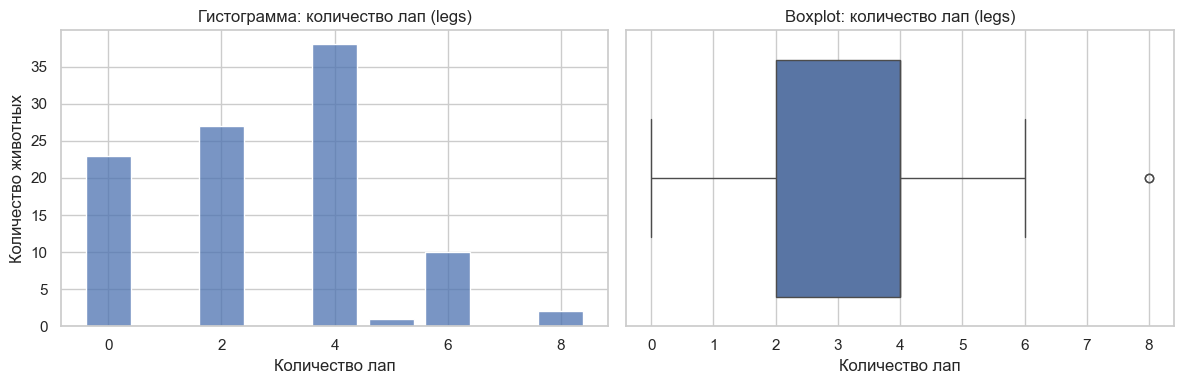

Сколько животных с каждым значением legs:
{0: 23, 2: 27, 4: 38, 5: 1, 6: 10, 8: 2}
Среднее: 2.84 | медиана: 4.0
Q1 = 2.0, Q3 = 4.0, IQR = 2.0. Допустимый диапазон: от -1.0 до 7.0
Выбросов по правилу 1.5*IQR: 2


,animal_name,legs,class_name
53,octopus,8,Invertebrate
72,scorpion,8,Invertebrate


In [ ]:
col = "legs"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(zoo[col], discrete=True, shrink=0.8, ax=axes[0])
axes[0].set_title("Гистограмма: количество лап (legs)")
axes[0].set_xlabel("Количество лап")
axes[0].set_ylabel("Количество животных")

sns.boxplot(x=zoo[col], ax=axes[1])
axes[1].set_title("Boxplot: количество лап (legs)")
axes[1].set_xlabel("Количество лап")

plt.tight_layout()
plt.show()

print("Сколько животных с каждым значением legs:")
print(zoo[col].value_counts().sort_index().to_dict())
print("Среднее:", round(zoo[col].mean(), 2), "| медиана:", zoo[col].median())

q1, q3 = zoo[col].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}. Допустимый диапазон: от {low} до {high}")

outliers = zoo[(zoo[col] < low) | (zoo[col] > high)]
print("Выбросов по правилу 1.5*IQR:", len(outliers))
display(outliers[["animal_name", "legs", "class_name"]])

**Вывод по гистограмме:** чаще всего встречаются животные с 4 лапами (38 из 101), потом с 2 (27) и без лап (23). Значения 5 и 8 лап очень редкие (1 и 2 животных). Распределение неравномерное, с несколькими пиками (0, 2 и 4 лапы), на нормальное оно не похоже.

**Вывод по boxplot:** по правилу 1.5·IQR (Q1 = 2, Q3 = 4, IQR = 2) допустимый диапазон от −1 до 7 лап. Выбросами оказались 2 животных с 8 лапами: `octopus` и `scorpion`. Это настоящие значения (оба из класса Invertebrate), а не ошибки, поэтому удалять их не нужно. Морская звезда с 5 лапами в допустимый диапазон входит.

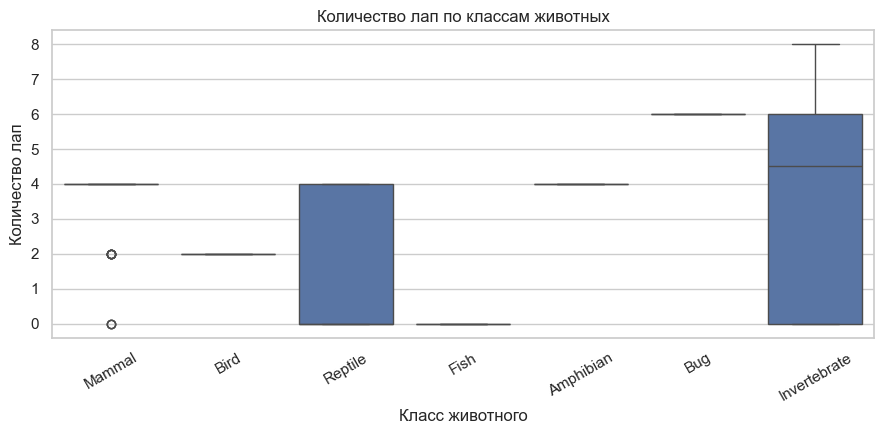

In [7]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=zoo, x="class_name", y="legs", order=class_order)
plt.title("Количество лап по классам животных")
plt.xlabel("Класс животного")
plt.ylabel("Количество лап")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Вывод:** количество лап хорошо различает классы: у всех птиц (Bird) 2 лапы, у всех рыб (Fish) 0, у всех Bug 6, у всех амфибий 4. Сильнее всего разброс у Invertebrate (от 0 до 8 лап). У Mammal почти у всех 4 лапы, поэтому животные с 0 лап (`dolphin`, `porpoise`, `seal`) и с 2 лапами выглядят на графике как выбросы внутри своего класса. Значит, признак `legs` будет полезен для будущей модели.

## 7. Категориальные (бинарные) признаки: частоты и редкие категории

Для бинарных признаков гистограмма и boxplot не подходят (всего два значения), поэтому смотрим, какую долю занимают значения 0 и 1.

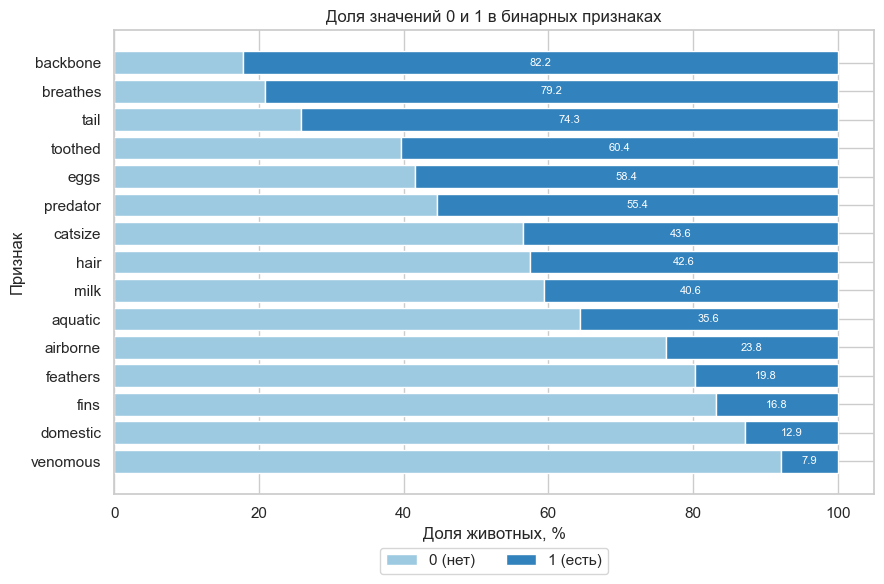

Признаки, у которых одно из значений встречается реже 5%: нет

Самые редкие единицы, %:
{'venomous': 7.9, 'domestic': 12.9, 'fins': 16.8}
Самые частые единицы, %:
{'tail': 74.3, 'breathes': 79.2, 'backbone': 82.2}


In [ ]:
share1 = (zoo[binary_cols].mean() * 100).sort_values()  
share0 = 100 - share1

plt.figure(figsize=(9, 6))
plt.barh(share1.index, share0, color="#9ecae1", label="0 (нет)")
plt.barh(share1.index, share1, left=share0, color="#3182bd", label="1 (есть)")
for i, v in enumerate(share1):
    plt.text(share0.iloc[i] + v / 2, i, f"{v:.1f}", ha="center", va="center", color="white", fontsize=8)
plt.title("Доля значений 0 и 1 в бинарных признаках")
plt.xlabel("Доля животных, %")
plt.ylabel("Признак")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
plt.show()

rare = {c: round(min(share1[c], 100 - share1[c]), 1) for c in binary_cols if min(share1[c], 100 - share1[c]) < 5}
print("Признаки, у которых одно из значений встречается реже 5%:", rare if rare else "нет")
print()
print("Самые редкие единицы, %:")
print(share1.head(3).round(1).to_dict())
print("Самые частые единицы, %:")
print(share1.tail(3).round(1).to_dict())

**Вывод:** доля единиц в бинарных признаках лежит между 7.9% и 82.2%, то есть сильных перекосов нет. Самые редкие единицы у `venomous` (7.9%, это 8 животных), `domestic` (12.9%) и `fins` (16.8%). Самые частые: `backbone` (82.2%), `breathes` (79.2%) и `tail` (74.3%). Значений реже 5% среди бинарных признаков нет.

In [10]:
legs_share = (zoo["legs"].value_counts(normalize=True).sort_index() * 100).round(1)
legs_tab = pd.DataFrame({"животных": zoo["legs"].value_counts().sort_index(), "%": legs_share})
display(legs_tab)
print("Редкие значения legs (< 5%):", legs_share[legs_share < 5].to_dict())
print()
print("Животные с редкими значениями legs:")
display(zoo[zoo["legs"].isin([5, 8])][["animal_name", "legs", "class_name"]])

print("animal_name: уникальных названий:", zoo["animal_name"].nunique(), "| всего строк:", len(zoo))

,животных,%
legs,,
0,23,22.8
2,27,26.7
4,38,37.6
5,1,1.0
6,10,9.9
8,2,2.0


Редкие значения legs (< 5%): {5: 1.0, 8: 2.0}

Животные с редкими значениями legs:


,animal_name,legs,class_name
53,octopus,8,Invertebrate
72,scorpion,8,Invertebrate
85,starfish,5,Invertebrate


animal_name: уникальных названий: 100 | всего строк: 101


**Вывод:** редкие значения `legs` (меньше 5%): 5 лап (1 животное, 1.0%) и 8 лап (2 животных, 2.0%). Это `starfish` и уже знакомые `octopus` и `scorpion`. Для `animal_name` график частот не нужен: 100 уникальных названий на 101 строку (`frog` повторяется), это просто название, а не признак для модели.

## 8. Корреляции

Столбец `class_type` в матрицу не берём: номера классов 1–7 — это категории, а не числа, и считать по ним корреляцию нельзя.

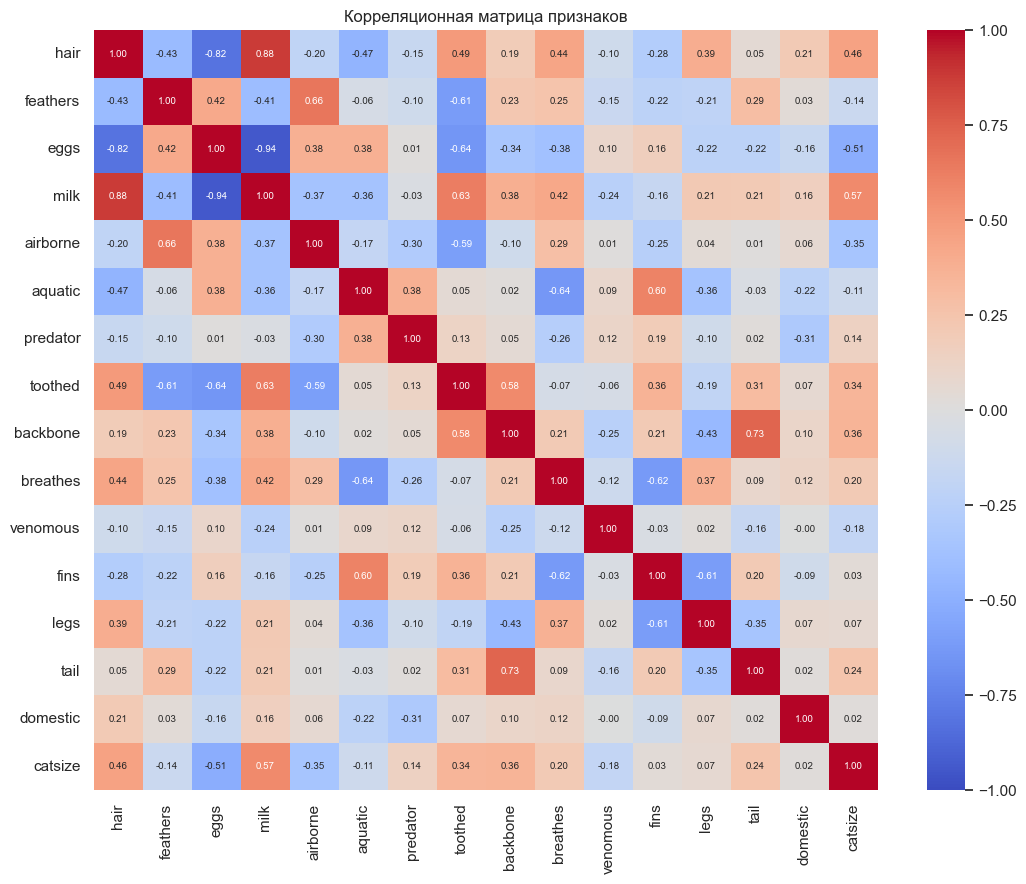

In [11]:
corr = zoo[features].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

**Вывод:** самая сильная связь у пары `eggs` и `milk`: −0.94 (кто откладывает яйца, обычно не даёт молоко). Ещё сильные связи: `hair` и `milk` (0.88), `eggs` и `hair` (−0.82), `backbone` и `tail` (0.73), `feathers` и `airborne` (0.66). Признаки `venomous`, `domestic` и `predator` слабо связаны с остальными (по модулю не больше 0.38). Все эти числа — просто связи между признаками, а не доказательство причин.

корреляция
eggs     milk           -0.94
hair     milk            0.88
         eggs           -0.82
backbone tail            0.73
feathers airborne        0.66
eggs     toothed        -0.64
aquatic  breathes       -0.64
milk     toothed         0.63

Признаки для диаграмм рассеяния: ['eggs', 'milk', 'hair', 'backbone', 'tail']


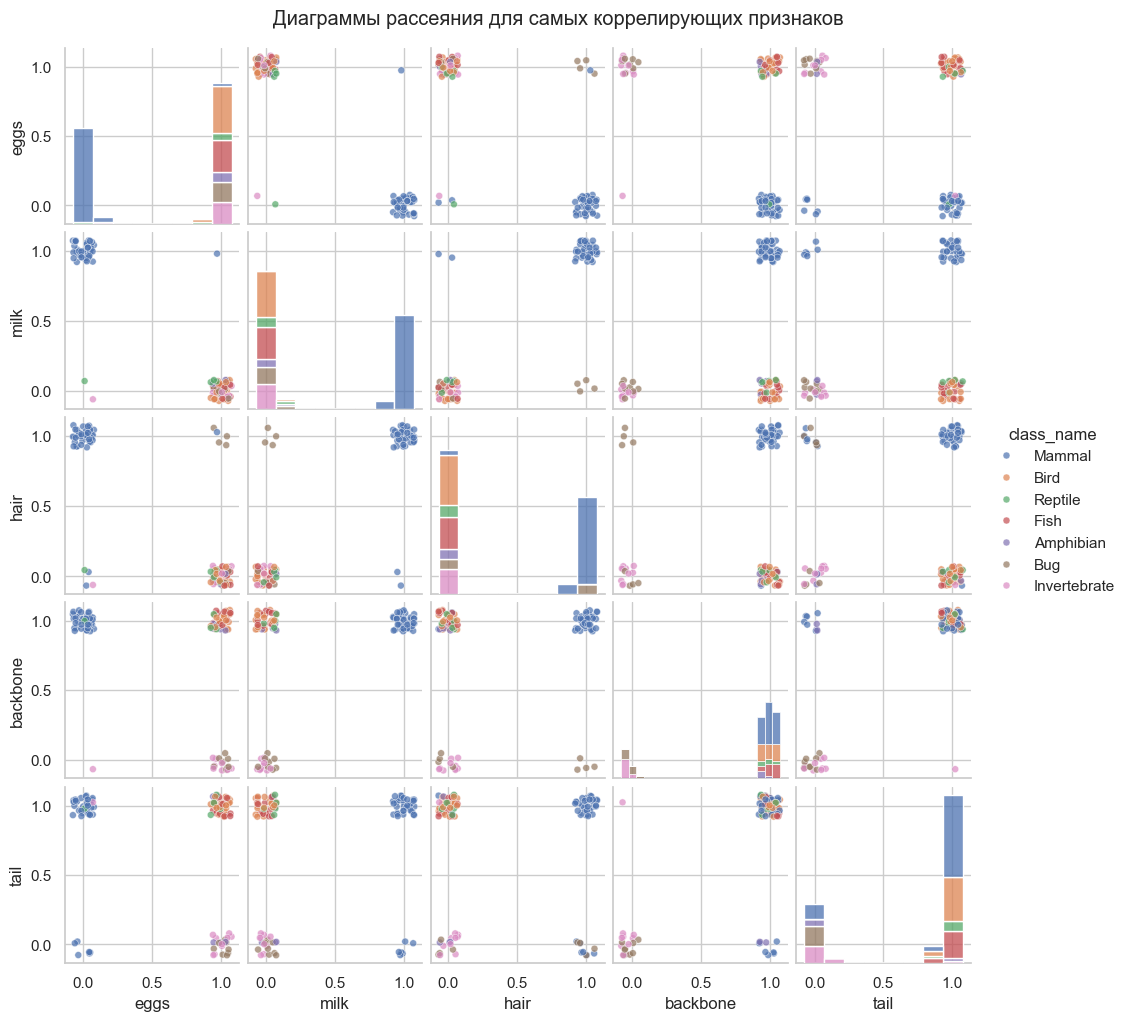

In [12]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(key=abs, ascending=False)
display(pairs.head(8).round(2).rename("корреляция").to_frame())

top_cols = list(dict.fromkeys([c for p in pairs.head(4).index for c in p]))
print("Признаки для диаграмм рассеяния:", top_cols)

rng = np.random.default_rng(42)
jit = zoo[top_cols].astype(float) + rng.uniform(-0.08, 0.08, size=(len(zoo), len(top_cols)))
jit["class_name"] = zoo["class_name"]

g = sns.pairplot(jit, hue="class_name", hue_order=class_order, diag_kind="hist",
                 plot_kws={"s": 25, "alpha": 0.7}, diag_kws={"multiple": "stack"}, height=2.0)
g.fig.suptitle("Диаграммы рассеяния для самых коррелирующих признаков", y=1.02)
plt.show()

**Вывод:** признаки принимают только 0 и 1, поэтому точки собираются в 4 группы (по углам); чтобы они не слипались, добавлен небольшой случайный сдвиг. Почти все точки пары `eggs`–`milk` лежат в двух противоположных углах: у млекопитающих `milk` = 1 и `eggs` = 0 (исключение — `platypus`, у него оба признака равны 1), а у остальных классов `milk` = 0. Все 8 пар из таблицы имеют модуль корреляции от 0.63 до 0.94. Но корреляция — не причина: `eggs` и `milk` связаны потому, что оба зависят от класса животного, а не потому что один признак вызывает другой.

## 9. Целевая переменная `class_type`: проверка дисбаланса

In [19]:
names = cls.set_index("Class_Number")["Class_Type"]
zoo["class_name"] = zoo["class_type"].map(names)

,класс,количество,%
class_type,,,
1,Mammal,41,40.6
2,Bird,20,19.8
3,Reptile,5,5.0
4,Fish,13,12.9
5,Amphibian,4,4.0
6,Bug,8,7.9
7,Invertebrate,10,9.9


Самый большой класс: 41 | самый маленький: 4 | разница в 10.2 раза
Количества по классам совпадают со справочником class.csv: True
Точность, если всегда отвечать самым частым классом: 40.6 %


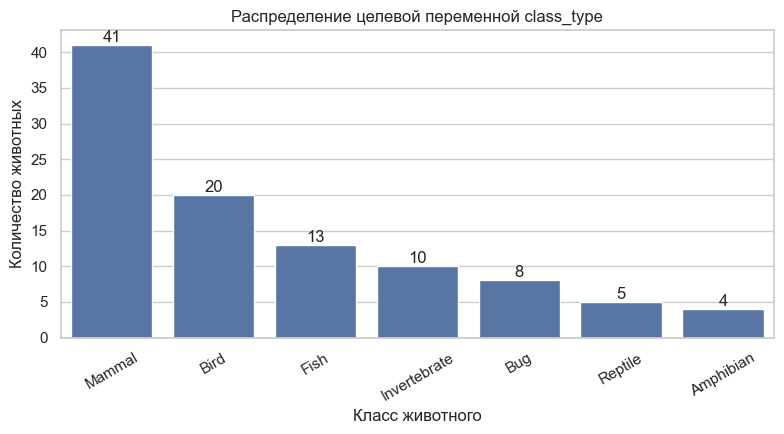

In [20]:
counts = zoo["class_type"].value_counts().sort_index()
tab = pd.DataFrame({
"класс": names.reindex(counts.index).values,
"количество": counts.values,
    "%": (counts / len(zoo) * 100).round(1).values,
}, index=counts.index)
display(tab)

print("Самый большой класс:", counts.max(), "| самый маленький:", counts.min(),
      "| разница в", round(counts.max() / counts.min(), 1), "раза")
print("Количества по классам совпадают со справочником class.csv:",
      bool((cls.set_index("Class_Number")["Number_Of_Animal_Species_In_Class"] == counts).all()))
print("Точность, если всегда отвечать самым частым классом:", round(counts.max() / len(zoo) * 100, 1), "%")

plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=zoo, x="class_name", order=zoo["class_name"].value_counts().index)
ax.bar_label(ax.containers[0])
plt.title("Распределение целевой переменной class_type")
plt.xlabel("Класс животного")
plt.ylabel("Количество животных")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Вывод:** классы распределены неравномерно: Mammal — 41 животное (40.6%), а Amphibian — всего 4 (4.0%); эти количества совпадают со справочником `class.csv`. Самый большой класс примерно в 10 раз больше самого маленького. Если модель будет всегда отвечать «Mammal», она окажется права в 40.6% случаев, поэтому одной точности (accuracy) для оценки мало. Классы Reptile и Amphibian (5 и 4 животных) редкие, на них модели будет труднее учиться.

In [16]:
display(pd.crosstab(zoo["milk"], zoo["class_name"]).reindex(columns=class_order))
display(pd.crosstab(zoo["feathers"], zoo["class_name"]).reindex(columns=class_order))

class_name,Mammal,Bird,Reptile,Fish,Amphibian,Bug,Invertebrate
milk,,,,,,,
0,0,20,5,13,4,8,10
1,41,0,0,0,0,0,0


class_name,Mammal,Bird,Reptile,Fish,Amphibian,Bug,Invertebrate
feathers,,,,,,,
0,41,0,5,13,4,8,10
1,0,20,0,0,0,0,0


**Вывод:** `milk` = 1 только у млекопитающих (все 41 из 41), а `feathers` = 1 только у птиц (все 20 из 20). Такие признаки почти сами называют класс, поэтому задача для модели может оказаться слишком лёгкой. Это стоит учесть, когда будем оценивать качество модели.

## 10. Итоговый отчёт: проблемы данных и как их устранить на следующем занятии

| № | Проблема данных | Где обнаружена | Как предполагается устранить |
|---|---|---|---|
| 1 | Пропусков нет | Раздел 5, `isnull().sum()` = 0 во всех столбцах | Ничего заполнять не нужно. После всех преобразований проверку пропусков повторим ещё раз. |
| 2 | Название `frog` встречается дважды, и строки отличаются значением `venomous` (0 и 1) | Раздел 5 | Понять, это два разных вида или ошибка. Если ошибка, оставить одну строку. Если разные виды, переименовать (например, `frog_1` и `frog_2`). |
| 3 | У 61 из 101 животного набор признаков совпадает с другим животным | Раздел 5 | Противоречий по классам нет, поэтому удалять строки необязательно. При делении на обучающую и тестовую части учесть, что повторы могут завысить оценку качества. |
| 4 | Выбросы в `legs`: 8 лап у `octopus` и `scorpion` | Раздел 6, boxplot и правило 1.5·IQR | Это реальные значения, поэтому оставляем. Удалять их нельзя: это потеряет информацию о классе Invertebrate. |
| 5 | Дисбаланс классов: 41 (Mammal) против 4 (Amphibian) | Раздел 9 | Делить данные с сохранением долей классов (`stratify`), оценивать модель по F1 и по каждому классу, а не только по accuracy; при необходимости взвесить классы (`class_weight`). |
| 6 | Признаки сильно связаны друг с другом (`eggs`–`milk` −0.94, `hair`–`milk` 0.88, `eggs`–`hair` −0.82), а `milk` и `feathers` почти сами определяют класс | Раздел 8 и раздел 9 | Из сильно связанных пар оставить один признак или сравнить модель с обоими. Проверить, насколько качество держится на одном–двух «подсказывающих» признаках. |
| 7 | Технические моменты: `class_type` записан числом, но это категория; `animal_name` — идентификатор; выборка маленькая (101 строка) | Разделы 3, 4 и 9 | Считать `class_type` категорией; `animal_name` в признаки не брать; из-за малого размера использовать кросс-валидацию. |

**Общий вывод.** Датасет аккуратный: пропусков нет, значения в допустимых пределах. Главные особенности: маленький размер, дисбаланс классов, повторяющееся `frog`, выбросы по `legs` (реальные) и признаки, которые почти сами задают класс.